In [16]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
rfm = pd.read_csv("../data/rfm.csv")

In [18]:
rfm_log = rfm[["Frequency","Recency","Monetary"]].map(np.log1p)
features = ["Recency", "Frequency", "Monetary"]
X_rfm = rfm_log[features]
X_scaled = StandardScaler().fit_transform(X=X_rfm)
X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=rfm.index
)
X_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,-8.025955e-17,1.000115,-2.341296,-0.661361,0.089926,0.844792,1.564198
Frequency,4338.0,-8.189750e-18,1.000115,-0.955214,-0.955214,-0.361583,0.653237,5.858535
Monetary,4338.0,-3.472454e-16,1.000115,-3.997811,-0.683580,-0.065109,0.657218,4.732381


In [19]:
silhouette_scores = []
inertias = []
for k in range(2,10):
    kmeans = KMeans(n_clusters=k,random_state=42,init="k-means++")
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled,labels,random_state=42)
    )

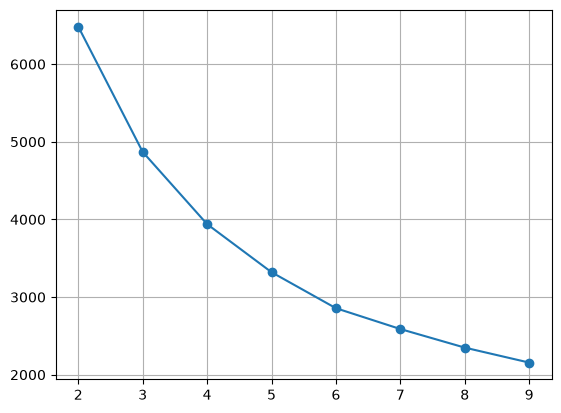

In [20]:
plt.plot(range(2,10),inertias,marker="o")
plt.grid()

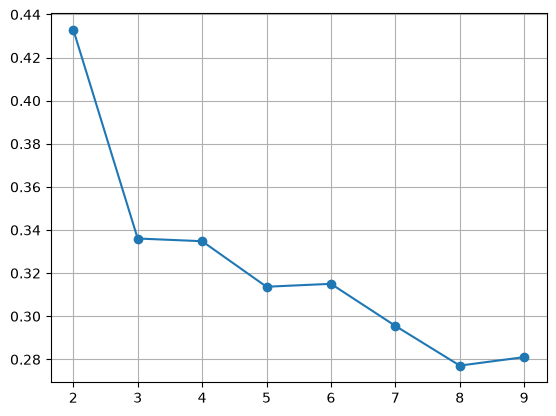

In [21]:
plt.plot(range(2,10),silhouette_scores,marker="o")
plt.grid()

In [22]:
kmeans = KMeans(n_clusters=3,init="k-means++")
rfm["Cluster"] = kmeans.fit_predict(X_scaled)
rfm[["Recency","Frequency","Monetary","Cluster"]].groupby("Cluster").describe().T

Cluster                    0             1              2
Recency   count  1910.000000   1694.000000     734.000000
          mean    164.325131     45.353601      14.622616
          std     106.079344     45.331875      21.887299
          min       4.000000      1.000000       1.000000
          25%      65.250000     16.000000       3.000000
          50%     156.000000     31.000000       9.000000
          75%     253.000000     61.000000      18.000000
          max     374.000000    366.000000     372.000000
Frequency count  1910.000000   1694.000000     734.000000
          mean      1.348168      3.498229      13.666213
          std       0.640631      1.626620      15.212242
          min       1.000000      1.000000       2.000000
          25%       1.000000      2.000000       7.000000
          50%       1.000000      3.000000      10.000000
          75%       2.000000      4.000000      15.000000
          max       6.000000     12.000000     209.000000
Monetary  count  1910.000000   1694.000000     734.000000
          mean    360.398927   1367.860645    8013.203011
          std     293.185951   2538.653985   20456.193923
          min       3.750000    102.450000     801.120000
          25%     164.470000    642.432500    2428.655000
          50%     297.500000   1009.955000    3739.235000
          75%     455.287500   1593.702500    6309.285000
          max    3096.000000  77183.600000  280206.020000

AttributeError: PathCollection.set() got an unexpected keyword argument 'camp'

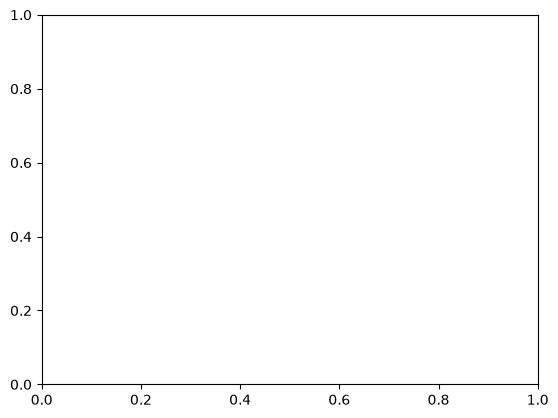

In [ ]:
pca = PCA(n_components=2)
pca_features = pd.DataFrame(
    pca.fit_transform(X_scaled),
    columns=["PC1","PC2"]
)
pca_features["Cluster"] = rfm["Cluster"]
sns.scatterplot(
    data=pca_features,
    x="PC1",
    y="PC2",
    hue="Cluster")

In [ ]:
labels = {
    0:"Gold",
    1:"Bronze",
    2:"Silver"
}
rfm["Cluster"] = rfm["Cluster"].map(labels)

In [ ]:
rfm.to_csv("../data/clients_rfm.csv")